# 🤖 Q-learning in a gridworld

A robot starts in the bottom-left corner of a small maze and has to find the **exit** (+1), while avoiding the **pit** (−1).
Nobody tells it the route: it learns from rewards alone, using **Q-learning**.

```
 T1  T2  T3  EXIT(+1)
 M1  ##  M3  PIT(−1)
 B1  B2  B3  B4
 ^start
```

The robot keeps a **Q-table** (a "cheat sheet"): for every square and every move (↑ ↓ ← →), a score saying how much reward it expects from there on.
After **every step** it corrects one score:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \cdot \big[\, r + \gamma \cdot \max_{a'} Q(s',a') - Q(s,a) \,\big]$$

*In words: new estimate = old estimate + α × (what I just got + the best I expect from where I landed − old estimate).*

### How to use this notebook
- Run the cells from top to bottom (**Runtime → Run all**).
- You don't need to write code. Change the values in the cells marked ✏️ and run them again.
- The cell marked ⚙️ is the "engine room". You may skip it.

## ⚙️ Engine room (you may skip this cell)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

# ---- the maze ----
LAYOUT = [["T1", "T2", "T3", "EXIT"],
          ["M1", "WALL", "M3", "PIT"],
          ["B1", "B2", "B3", "B4"]]
POS = {LAYOUT[r][c]: (r, c) for r in range(3) for c in range(4)}
STATES = [n for row in LAYOUT for n in row if n not in ("WALL", "EXIT", "PIT")]
ACTIONS = ["up", "down", "left", "right"]
ARROW = {"up": "↑", "down": "↓", "left": "←", "right": "→"}
MOVE = {"up": (-1, 0), "down": (1, 0), "left": (0, -1), "right": (0, 1)}
REWARD = {"EXIT": 1.0, "PIT": -1.0}
START = "B1"

def step(state, action, rng, slip=0.0, step_cost=0.0):
    """Move the robot. Returns (new_state, reward, done). Bumping into the wall or the edge = stay put.
    With probability `slip` the robot slips and moves in a random direction instead."""
    if slip > 0 and rng.random() < slip:
        action = ACTIONS[rng.integers(4)]
    r, c = POS[state]; dr, dc = MOVE[action]
    nr, nc = r + dr, c + dc
    if not (0 <= nr < 3 and 0 <= nc < 4) or LAYOUT[nr][nc] == "WALL":
        nr, nc = r, c
    new = LAYOUT[nr][nc]
    reward = REWARD.get(new, 0.0) - step_cost
    return new, reward, new in REWARD

def new_q():
    return pd.DataFrame(0.0, index=STATES, columns=ACTIONS)

def best_next(Q, s_new):
    return 0.0 if s_new in REWARD else Q.loc[s_new].max()      # the exit and the pit end the episode: no future

def update(Q, s, a, r, s_new, alpha, gamma, verbose=False):
    old = Q.loc[s, a]
    nxt = best_next(Q, s_new)
    Q.loc[s, a] = old + alpha * (r + gamma * nxt - old)
    if verbose:
        print(f"{s} --{ARROW[a]}--> {s_new:4s} reward {r:+.0f}:   Q({s},{ARROW[a]}) = {old:.3f} + {alpha} × ({r:.0f} + {gamma} × {nxt:.3f} − {old:.3f}) = {Q.loc[s, a]:.3f}")

def choose(Q, s, epsilon, rng):
    if rng.random() < epsilon:
        return ACTIONS[rng.integers(4)]                         # explore
    row = Q.loc[s].values
    best = np.flatnonzero(row == row.max())
    return ACTIONS[rng.choice(best)]                            # exploit (ties broken at random)

def run_episode(Q, alpha, gamma, epsilon, rng, slip=0.0, step_cost=0.0, max_steps=100):
    s, steps, total = START, 0, 0.0
    while steps < max_steps:
        a = choose(Q, s, epsilon, rng)
        s_new, r, done = step(s, a, rng, slip, step_cost)
        update(Q, s, a, r, s_new, alpha, gamma)
        s, steps, total = s_new, steps + 1, total + r
        if done: break
    return steps, total, s

def train(episodes=500, alpha=0.5, gamma=0.9, epsilon=0.2, slip=0.0, step_cost=0.0, seed=0, snapshots=()):
    rng = np.random.default_rng(seed); Q = new_q(); log, snaps = [], {}
    for ep in range(1, episodes + 1):
        steps, total, end = run_episode(Q, alpha, gamma, epsilon, rng, slip, step_cost)
        log.append({"episode": ep, "steps": steps, "reward": total, "ended in": end})
        if ep in snapshots: snaps[ep] = Q.copy()
    return Q, pd.DataFrame(log), snaps

def draw(Q, ax=None, title="", show_all=True):
    """Draw the maze. Each square shows its 4 scores (one triangle per move) and the best move as an arrow."""
    if ax is None: fig, ax = plt.subplots(figsize=(7, 5.2))
    cmap = plt.get_cmap("RdYlGn")
    for r in range(3):
        for c in range(4):
            name = LAYOUT[r][c]; x, y = c, 2 - r
            if name in ("WALL", "EXIT", "PIT"):
                col = {"WALL": "#2F4D5D", "EXIT": "#1D8DB0", "PIT": "#C00000"}[name]
                ax.add_patch(Rectangle((x, y), 1, 1, color=col))
                ax.text(x + .5, y + .5, {"WALL": "wall", "EXIT": "EXIT\n+1", "PIT": "PIT\n−1"}[name],
                        ha="center", va="center", color="white", fontsize=12, fontweight="bold")
                continue
            q = Q.loc[name]
            tri = {"up": [(x, y + 1), (x + 1, y + 1), (x + .5, y + .5)], "down": [(x, y), (x + 1, y), (x + .5, y + .5)],
                   "left": [(x, y), (x, y + 1), (x + .5, y + .5)], "right": [(x + 1, y), (x + 1, y + 1), (x + .5, y + .5)]}
            off = {"up": (0, .33), "down": (0, -.33), "left": (-.33, 0), "right": (.33, 0)}
            for a in ACTIONS:
                ax.add_patch(Polygon(tri[a], closed=True, facecolor=cmap((q[a] + 1) / 2), edgecolor="white", lw=1))
                if show_all:
                    ax.text(x + .5 + off[a][0], y + .5 + off[a][1], f"{q[a]:.2f}", ha="center", va="center", fontsize=8)
            if q.max() != 0 or q.min() != 0:
                ax.text(x + .5, y + .5, ARROW[q.idxmax()], ha="center", va="center", fontsize=18, fontweight="bold")
            ax.text(x + .04, y + .96, name + (" start" if name == START else ""), ha="left", va="top", fontsize=8, color="#2F4D5D",
                    bbox=dict(facecolor="white", alpha=0.7, lw=0, pad=1))
    ax.set_xlim(0, 4); ax.set_ylim(0, 3); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title)
    return ax

def show_route(Q, start=START, max_steps=20):
    s, route = start, [start]
    for _ in range(max_steps):
        a = Q.loc[s].idxmax()
        s, _, done = step(s, a, np.random.default_rng(0))
        route.append(s)
        if done: break
    print(f"Route from {start} when always following the highest score:", " → ".join(route))
print("Ready.")

Ready.


## 1. The empty cheat sheet
At the start, the robot knows nothing: all 36 scores (9 squares × 4 moves) are 0.

,up,down,left,right
T1,0.0,0.0,0.0,0.0
T2,0.0,0.0,0.0,0.0
T3,0.0,0.0,0.0,0.0
M1,0.0,0.0,0.0,0.0
M3,0.0,0.0,0.0,0.0
B1,0.0,0.0,0.0,0.0
B2,0.0,0.0,0.0,0.0
B3,0.0,0.0,0.0,0.0
B4,0.0,0.0,0.0,0.0


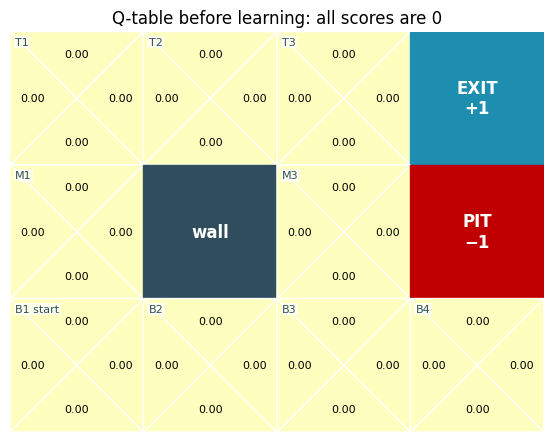

In [2]:
Q = new_q()
display(Q)
draw(Q, title="Q-table before learning: all scores are 0"); plt.show()

## 2. The worked example from the slides, step by step
We let the robot walk three times along the top row to the exit (T1 → T2 → T3 → EXIT), with **α = 0.5** and **γ = 0.9**.
Watch how the good news flows back, one square per episode.

In [3]:
Q = new_q()
alpha, gamma = 0.5, 0.9
episodes = [["T3"], ["T2", "T3"], ["T1", "T2", "T3"]]      # the squares from which the robot moves right
for k, squares in enumerate(episodes, 1):
    print(f"--- Episode {k} ---")
    for s in squares:
        s_new, r, done = step(s, "right", None)
        update(Q, s, "right", r, s_new, alpha, gamma, verbose=True)
display(Q.loc[["T1", "T2", "T3"], ["right"]].round(3))

--- Episode 1 ---
T3 --→--> EXIT reward +1:   Q(T3,→) = 0.000 + 0.5 × (1 + 0.9 × 0.000 − 0.000) = 0.500
--- Episode 2 ---
T2 --→--> T3   reward +0:   Q(T2,→) = 0.000 + 0.5 × (0 + 0.9 × 0.500 − 0.000) = 0.225
T3 --→--> EXIT reward +1:   Q(T3,→) = 0.500 + 0.5 × (1 + 0.9 × 0.000 − 0.500) = 0.750
--- Episode 3 ---
T1 --→--> T2   reward +0:   Q(T1,→) = 0.000 + 0.5 × (0 + 0.9 × 0.225 − 0.000) = 0.101
T2 --→--> T3   reward +0:   Q(T2,→) = 0.225 + 0.5 × (0 + 0.9 × 0.750 − 0.225) = 0.450
T3 --→--> EXIT reward +1:   Q(T3,→) = 0.750 + 0.5 × (1 + 0.9 × 0.000 − 0.750) = 0.875


,right
T1,0.101
T2,0.450
T3,0.875


*Note episode 2: moving from T2 to T3 gives **no reward**, yet the score goes up, because T3 already looks good.*

## 3. Let the robot learn on its own
Now the robot starts with an empty cheat sheet and explores by itself: with probability **ε** it makes a random move (explore),
otherwise it takes the move with the highest score (exploit). Each episode ends at the exit or in the pit.

✏️ Change the settings and run again.

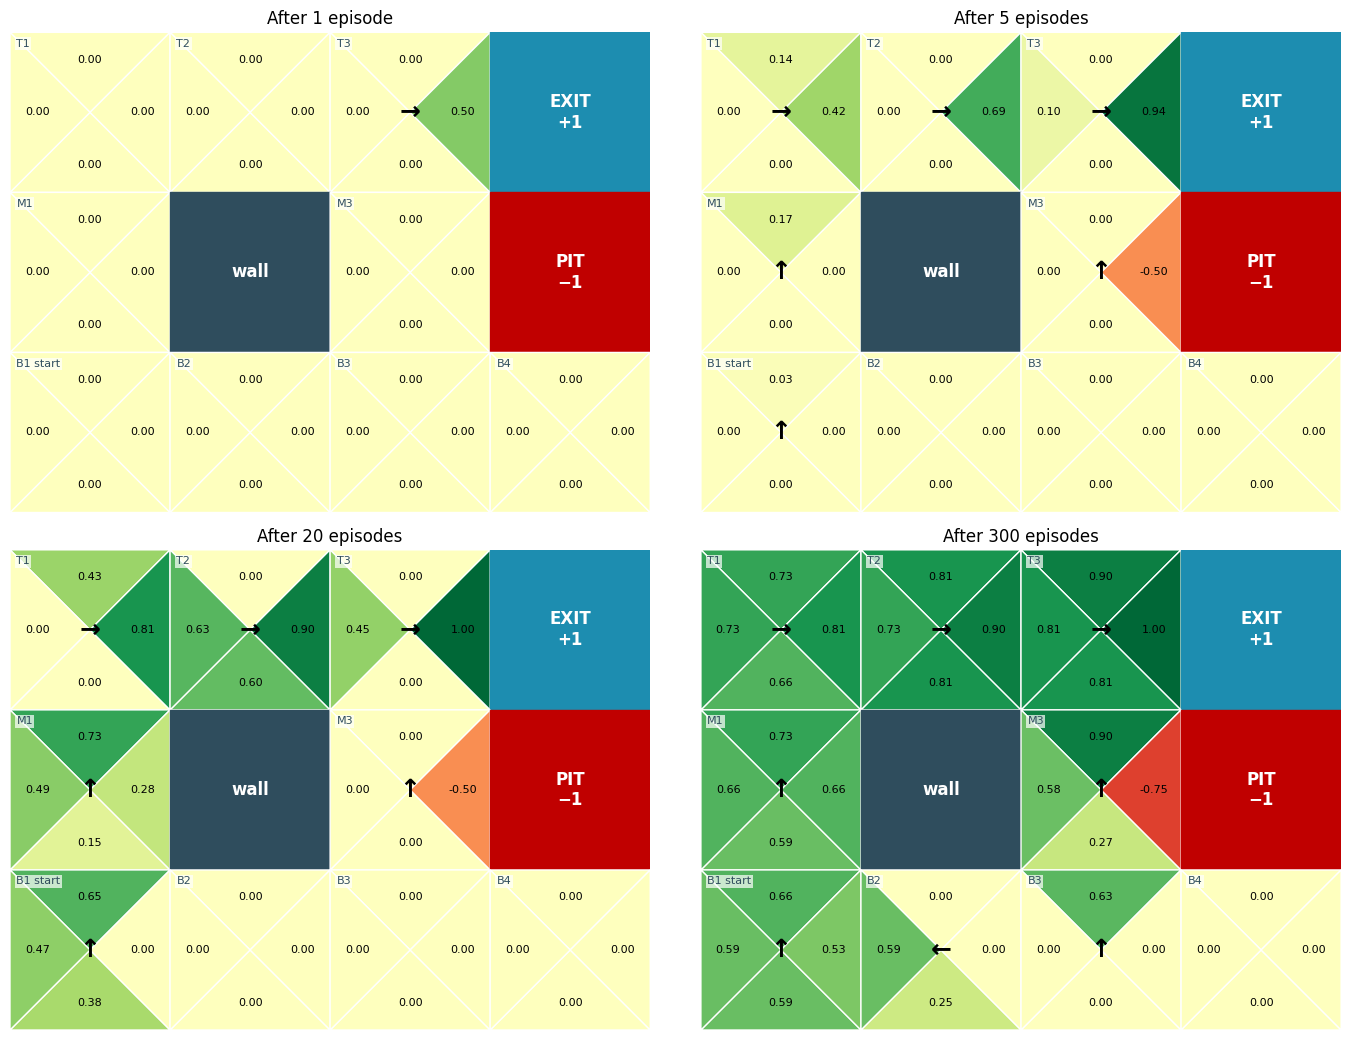

Route from B1 when always following the highest score: B1 → M1 → T1 → T2 → T3 → EXIT


In [4]:
EPISODES = 300      # number of episodes
ALPHA    = 0.5      # learning rate
GAMMA    = 0.9      # discount
EPSILON  = 0.2      # share of random (exploration) moves

SNAPS = (1, 5, 20, EPISODES)
Q, log, snaps = train(EPISODES, ALPHA, GAMMA, EPSILON, snapshots=SNAPS)

fig, axes = plt.subplots(2, 2, figsize=(14, 10.5))
for ax, ep in zip(axes.flat, SNAPS):
    draw(snaps[ep], ax=ax, title=f"After {ep} episode{'s' if ep > 1 else ''}")
plt.tight_layout(); plt.show()
show_route(Q)

### How quickly does it learn?
Number of steps the robot needed to finish each episode (fewer is better), and how each episode ended.

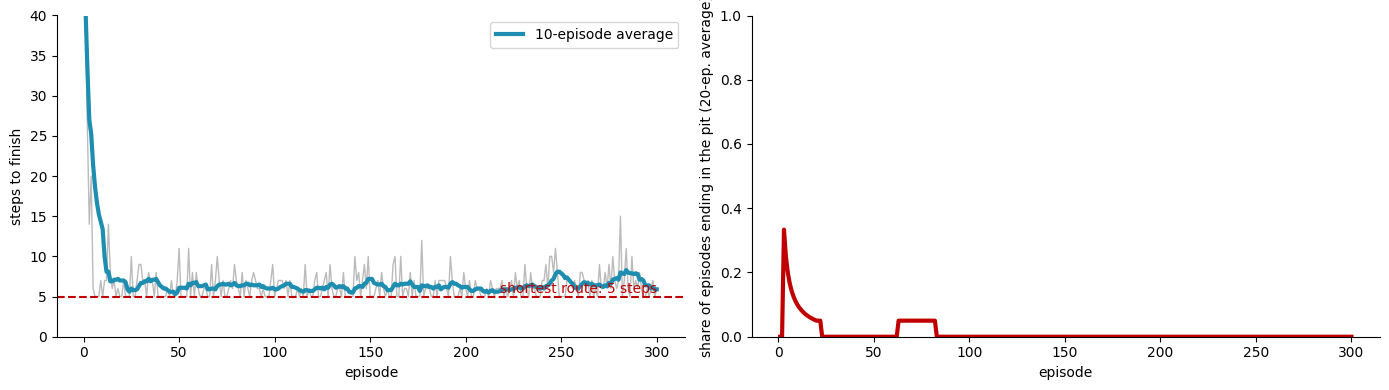

The learned Q-table:


,up,down,left,right
T1,0.73,0.66,0.73,0.81
T2,0.81,0.81,0.73,0.90
T3,0.90,0.81,0.81,1.00
M1,0.73,0.59,0.66,0.66
M3,0.90,0.27,0.58,-0.75
B1,0.66,0.59,0.59,0.53
B2,0.00,0.25,0.59,0.00
B3,0.63,0.00,0.00,0.00
B4,0.00,0.00,0.00,0.00


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(log["episode"], log["steps"], color="#BBBBBB", lw=1)
ax[0].plot(log["episode"], log["steps"].rolling(10, min_periods=1).mean(), color="#1D8DB0", lw=3, label="10-episode average")
ax[0].axhline(5, ls="--", color="#C00000"); ax[0].text(len(log), 5.5, "shortest route: 5 steps", ha="right", color="#C00000")
ax[0].set_xlabel("episode"); ax[0].set_ylabel("steps to finish"); ax[0].set_ylim(0, 40); ax[0].legend()
pit = (log["ended in"] == "PIT").astype(int).rolling(20, min_periods=1).mean()
ax[1].plot(log["episode"], pit, color="#C00000", lw=3)
ax[1].set_xlabel("episode"); ax[1].set_ylabel("share of episodes ending in the pit (20-ep. average)"); ax[1].set_ylim(0, 1)
for a in ax:
    for s_ in ["top", "right"]: a.spines[s_].set_visible(False)
plt.tight_layout(); plt.show()
print("The learned Q-table:")
display(Q.round(2))

*Why does the robot still fall in the pit now and then, even after learning? (Hint: look at ε.)*

## 4. ✏️ Experiments
**Experiment 1: no exploration.** Set ε = 0: the robot always takes the highest score. Does it still find the exit? Is its route the shortest?

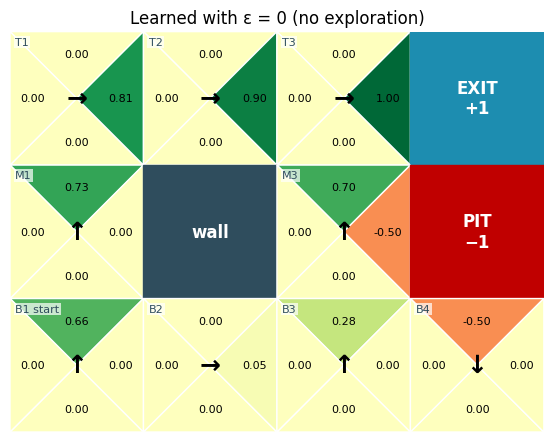

Route from B1 when always following the highest score: B1 → M1 → T1 → T2 → T3 → EXIT
Average steps in the last 50 episodes: 5.0


In [6]:
Q0, log0, _ = train(episodes=300, epsilon=0.0, seed=3)
draw(Q0, title="Learned with ε = 0 (no exploration)"); plt.show()
show_route(Q0)
print("Average steps in the last 50 episodes:", log0["steps"].tail(50).mean())

*With all scores at 0, ties are broken at random, so the robot does wander at first. But as soon as one route has worked, it keeps repeating it.
Try a few different `seed` values: sometimes it gets lucky, sometimes it sticks with a detour or squares stay unexplored. This is the exploration–exploitation trade-off again!*

**Experiment 2: a slippery floor.** With probability 20%, the robot slips and moves in a random direction. What happens to the scores near the pit? Which route does it prefer now?

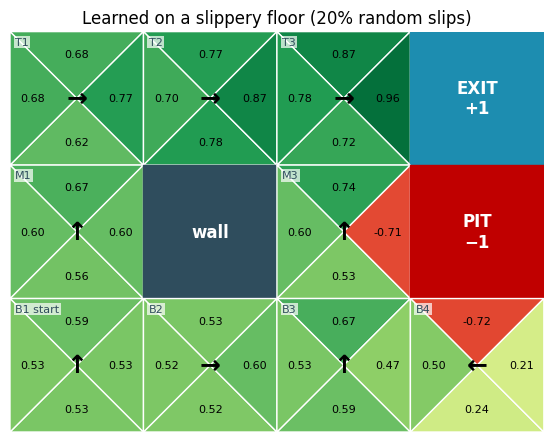

Route from B1 when always following the highest score: B1 → M1 → T1 → T2 → T3 → EXIT


In [7]:
Qs, logs, _ = train(episodes=8000, slip=0.2, alpha=0.05, epsilon=0.3, seed=1)   # takes ~10 seconds
draw(Qs, title="Learned on a slippery floor (20% random slips)"); plt.show()
show_route(Qs)

*Scores are lower (the robot can't be sure to reach the exit), and moves next to the pit become risky. Compare B1: going up (top row, away from the pit) now scores a bit higher than going right (the bottom route passes M3, next to the pit). Both routes are 5 steps long: the robot has learned to play it safe.*

**Experiment 3: the discount γ.** Compare γ = 0.9 with γ = 0.5. What happens to the scores far from the exit?

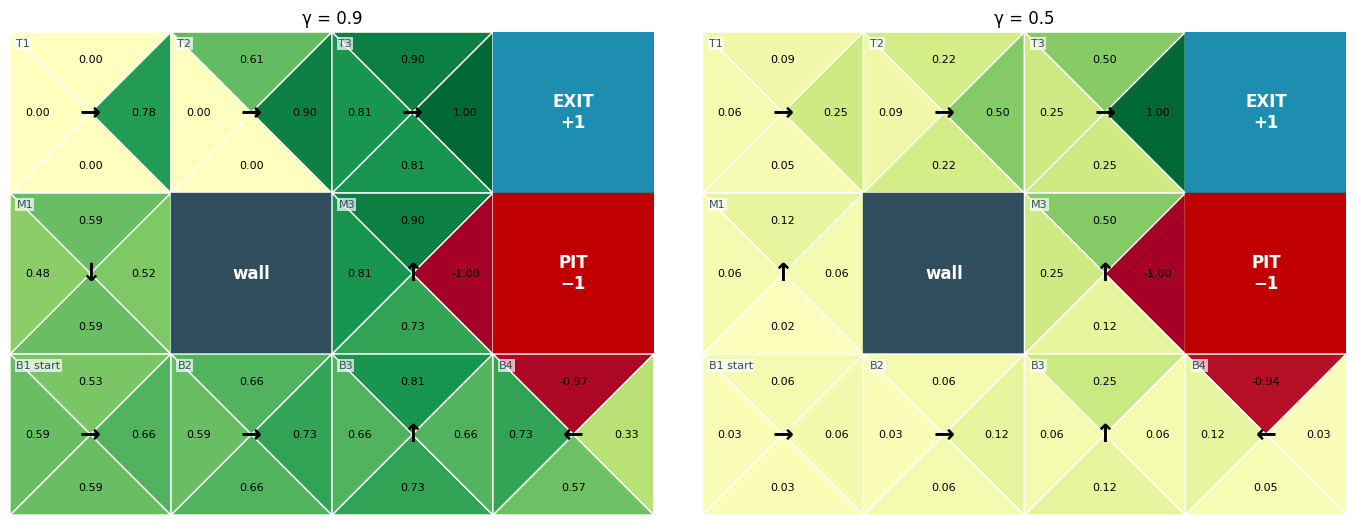

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, g in zip(axes, [0.9, 0.5]):
    Qg, _, _ = train(episodes=500, gamma=g, seed=2)
    draw(Qg, ax=ax, title=f"γ = {g}")
plt.tight_layout(); plt.show()

*With a low γ, rewards far in the future count for little: the scores far from the exit become very small. A business parallel: how much does a firm value a customer's future revenue versus this month's margin?*

**Experiment 4: a badly designed reward.** Now every step costs 0.8 (e.g. time or fuel), and the pit still costs 1. Look at square B4: what does the robot learn to do there, and why?

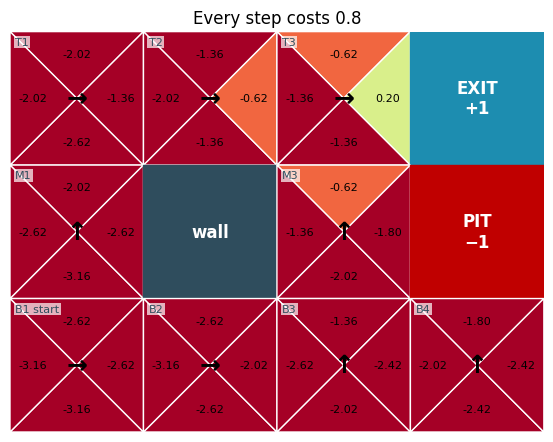

Route from B1 when always following the highest score: B1 → B2 → B3 → M3 → T3 → EXIT
Route from B4 when always following the highest score: B4 → PIT


In [9]:
Qc, _, _ = train(episodes=3000, step_cost=0.8, epsilon=0.3, seed=1)
draw(Qc, title="Every step costs 0.8"); plt.show()
show_route(Qc, start="B1")
show_route(Qc, start="B4")

*From B4, walking to the exit takes 4 steps (4 × 0.8 = 3.2 in costs, for a reward of 1); jumping into the pit costs only 1.8. The robot does exactly what the rewards tell it to: it "gives up". The reward you define is the behaviour you get!*

## 5. Discussion questions
1. In your own words: how does the reward at the exit reach the starting square, although the robot only ever looks one step ahead?
2. Why does Q-learning need exploration? What would you choose for ε at the start, and later on?
3. This maze has 9 squares. What happens to the Q-table for a game of chess, or for a bank's customers described by 50 features? (Hint: deep Q-learning.)
4. The reward design changed the robot's behaviour (Experiment 4). Give a business example where a badly chosen reward leads to unwanted behaviour.